In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
image = cv2.imread('lan_img1.jpg.jpeg')
if image is None:
    raise FileNotFoundError("road.jpg was not found. Place road.jpg in the same folder as this notebook.")

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

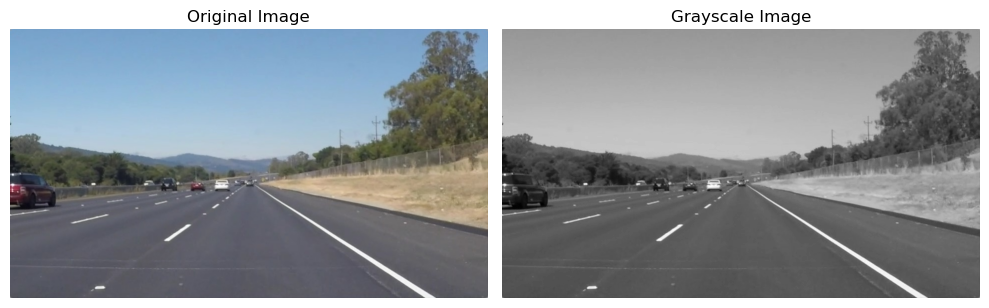

In [5]:
plt.figure(figsize=(10,5))

###
# Your Code Here
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
threshold = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)

In [7]:
height, width = threshold[1].shape

mask = np.zeros_like(threshold[1])

polygon = np.array([[
    (0, height),
    (width // 2 - 60, height // 2 + 60),
    (width // 2 + 60, height // 2 + 60),
    (width, height)
]], np.int32)

cv2.fillPoly(mask, polygon, 255)

roi = cv2.bitwise_and(threshold[1], mask)

In [8]:
edges = cv2.Canny(roi, 50, 150)

In [9]:
blurred = cv2.GaussianBlur(edges, (5,5), 0)

In [11]:
lines = cv2.HoughLinesP(
    blurred,
    rho=1,
    theta=np.pi/180,
    threshold=50,
    minLineLength=50,
    maxLineGap=100
)

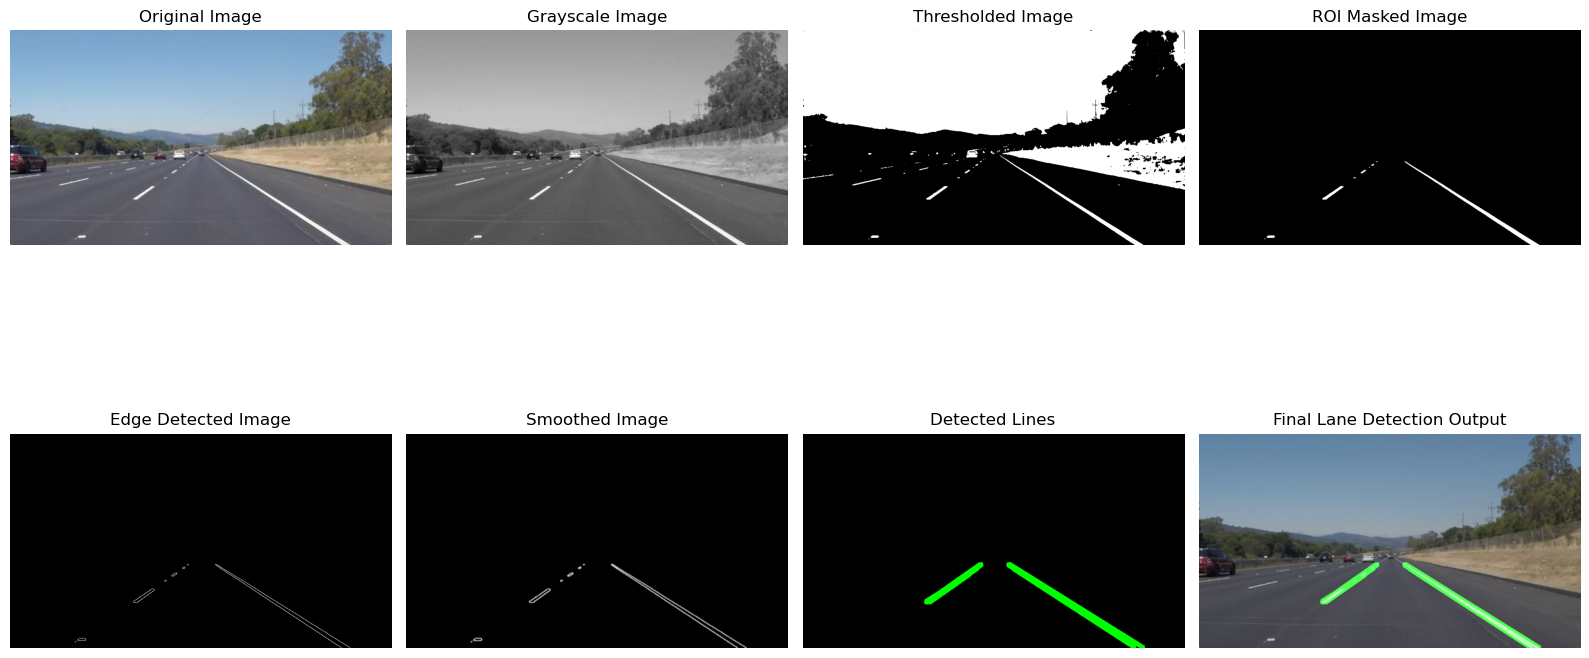

In [14]:
# Already implemented
# (Do not modify)

# Step 10: Lane Detection Logic

line_image = np.zeros_like(image)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(line_image, (x1, y1), (x2, y2), (0, 255, 0), 5)

final_output = cv2.addWeighted(image, 0.8, line_image, 1.0, 0)
plt.figure(figsize=(16,10))

plt.subplot(2,4,1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2,4,2)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(2,4,3)
plt.imshow(threshold[1], cmap='gray')
plt.title("Thresholded Image")
plt.axis("off")

plt.subplot(2,4,4)
plt.imshow(roi, cmap='gray')
plt.title("ROI Masked Image")
plt.axis("off")

plt.subplot(2,4,5)
plt.imshow(edges, cmap='gray')
plt.title("Edge Detected Image")
plt.axis("off")

plt.subplot(2,4,6)
plt.imshow(blurred, cmap='gray')
plt.title("Smoothed Image")
plt.axis("off")

plt.subplot(2,4,7)
plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines")
plt.axis("off")

plt.subplot(2,4,8)
plt.imshow(cv2.cvtColor(final_output, cv2.COLOR_BGR2RGB))
plt.title("Final Lane Detection Output")
plt.axis("off")

plt.tight_layout()
plt.show()